# Role 2 — Data Pipeline Fashion-MNIST

**Pemilik role: Hafid.** Notebook ini menjelaskan dan menjalankan modul data untuk Mini DDPM.
Sumber data: [repository resmi Zalando](https://github.com/zalandoresearch/fashion-mnist).
Tidak memakai model pretrained atau kode tutorial diffusion. Kode pipeline berada di `src/data/`.

Jalankan dari atas ke bawah menggunakan environment yang sudah memasang `requirements.txt` dan `ipykernel`.
Notebook ini memeriksa data, **belum melatih DDPM**.

## 1. Temukan folder proyek

Notebook bisa dibuka dari root repository atau folder `notebooks/`. Jalur data di config dihitung dari root proyek.

In [1]:
from pathlib import Path
import os

candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next((p for p in candidates if (p / "src/data/dataset.py").is_file()), None)
if PROJECT_ROOT is None:
    raise RuntimeError("Buka notebook dari folder repository GenerativeAI atau subfoldernya.")
os.chdir(PROJECT_ROOT)
print("Root proyek ditemukan; src/data/dataset.py tersedia.")

Root proyek ditemukan; src/data/dataset.py tersedia.


## 2. Baca konfigurasi dan tetapkan seed

Semua hyperparameter data dibaca dari YAML. `seed_data` dipanggil sekali saat memulai run.
Default `num_workers=0` mudah dijalankan pada Windows maupun notebook. Untuk data offline,
ubah `download` menjadi `false` setelah file raw tersedia.

In [2]:
from dataclasses import asdict
import json
import torch
from src.data import CLASS_NAMES, load_data_config, seed_data, build_dataloaders, to_display

config = load_data_config("configs/default.yaml")
seed_data(config.seed)
print(json.dumps(asdict(config), indent=2))

{
  "root": "data",
  "val_size": 5000,
  "batch_size": 128,
  "num_workers": 0,
  "pin_memory": false,
  "download": true,
  "horizontal_flip_p": 0.5,
  "drop_last_train": false,
  "seed": 42
}


## 3. Bangun DataLoader dari dataset nyata

Pipeline mengunduh file Fashion-MNIST dari folder `data/fashion` milik Zalando melalui HTTPS.
Torchvision memeriksa checksum saat download. Dari 60.000 gambar training resmi,
55.000 digunakan untuk train dan 5.000 untuk validasi; test resmi berisi 10.000 gambar terpisah.

In [3]:
loaders = build_dataloaders(config)
for name in ("train", "val", "test"):
    loader = getattr(loaders, name)
    print(f"{name:5s}: {len(loader.dataset):,} gambar, {len(loader)} batch")

train: 55,000 gambar, 430 batch
val  : 5,000 gambar, 40 batch
test : 10,000 gambar, 79 batch


## 4. Verifikasi kontrak tensor

Urutan transformasi: tensor [0,1] → horizontal flip pada train saja → padding hitam 2 piksel → normalisasi [-1,1].
`dataset[i]` menghasilkan **gambar saja**, bukan pasangan `(gambar, label)`.
Padding dilakukan sebelum normalisasi agar batas hitam bernilai -1.

In [4]:
for name in ("train", "val", "test"):
    images = next(iter(getattr(loaders, name)))
    assert isinstance(images, torch.Tensor)
    assert tuple(images.shape[1:]) == (1, 32, 32)
    assert images.dtype == torch.float32 and torch.isfinite(images).all()
    assert -1 <= images.min() and images.max() <= 1
    assert (images[..., :2, :] == -1).all()
    assert (images[..., -2:, :] == -1).all()
    assert (images[..., :2] == -1).all()
    assert (images[..., -2:] == -1).all()
    print(name, tuple(images.shape), images.dtype, "range:", float(images.min()), float(images.max()))
print("Kontrak tensor semua split: LULUS")

train (128, 1, 32, 32) torch.float32 range: -1.0 1.0
val (128, 1, 32, 32) torch.float32 range: -1.0 1.0
test (128, 1, 32, 32) torch.float32 range: -1.0 1.0
Kontrak tensor semua split: LULUS


## 5. Buktikan pemisahan data dan sebaran kelas

Indeks train/validasi mengacu pada sumber training resmi yang sama. Indeks test berasal dari sumber test yang berbeda,
sehingga nomor indeks test tidak boleh dibandingkan langsung dengan nomor indeks training.
Label tetap dipakai untuk stratifikasi dan diagnostik, tetapi tidak diberikan ke model DDPM.

In [5]:
train_ids = set(loaders.train.dataset.indices)
val_ids = set(loaders.val.dataset.indices)
assert train_ids.isdisjoint(val_ids)
assert train_ids | val_ids == set(range(60000))
assert loaders.train.dataset.base_dataset is loaders.val.dataset.base_dataset
assert loaders.test.dataset.base_dataset is not loaders.train.dataset.base_dataset
assert not loaders.test.dataset.base_dataset.train
assert not loaders.val.dataset.training and not loaders.test.dataset.training
print("Overlap train-validasi:", len(train_ids & val_ids))
print(f"{'Kelas':15s} {'Train':>7s} {'Val':>7s} {'Test':>7s}")
counts = [torch.bincount(getattr(loaders, split).dataset.targets.long(), minlength=10)
          for split in ("train", "val", "test")]
for i, name in enumerate(CLASS_NAMES):
    print(f"{name:15s} {int(counts[0][i]):7d} {int(counts[1][i]):7d} {int(counts[2][i]):7d}")

Overlap train-validasi: 0
Kelas             Train     Val    Test
T-shirt/top        5500     500    1000
Trouser            5500     500    1000
Pullover           5500     500    1000
Dress              5500     500    1000
Coat               5500     500    1000
Sandal             5500     500    1000
Shirt              5500     500    1000
Sneaker            5500     500    1000
Bag                5500     500    1000
Ankle boot         5500     500    1000


## 6. Simpan bukti pemeriksaan dan lihat hasil

Laporan menyimpan satu batch pemeriksaan per split, jumlah kelas, versi runtime dan indeks split.
Gambar yang ditampilkan adalah **data asli setelah preprocessing**, bukan hasil generasi DDPM.
Loader baru dipakai supaya preview selalu dapat direproduksi dari seed yang sama.

Laporan tersimpan: reports/data/summary.json
Indeks split tersimpan: reports/data/split_indices.npz


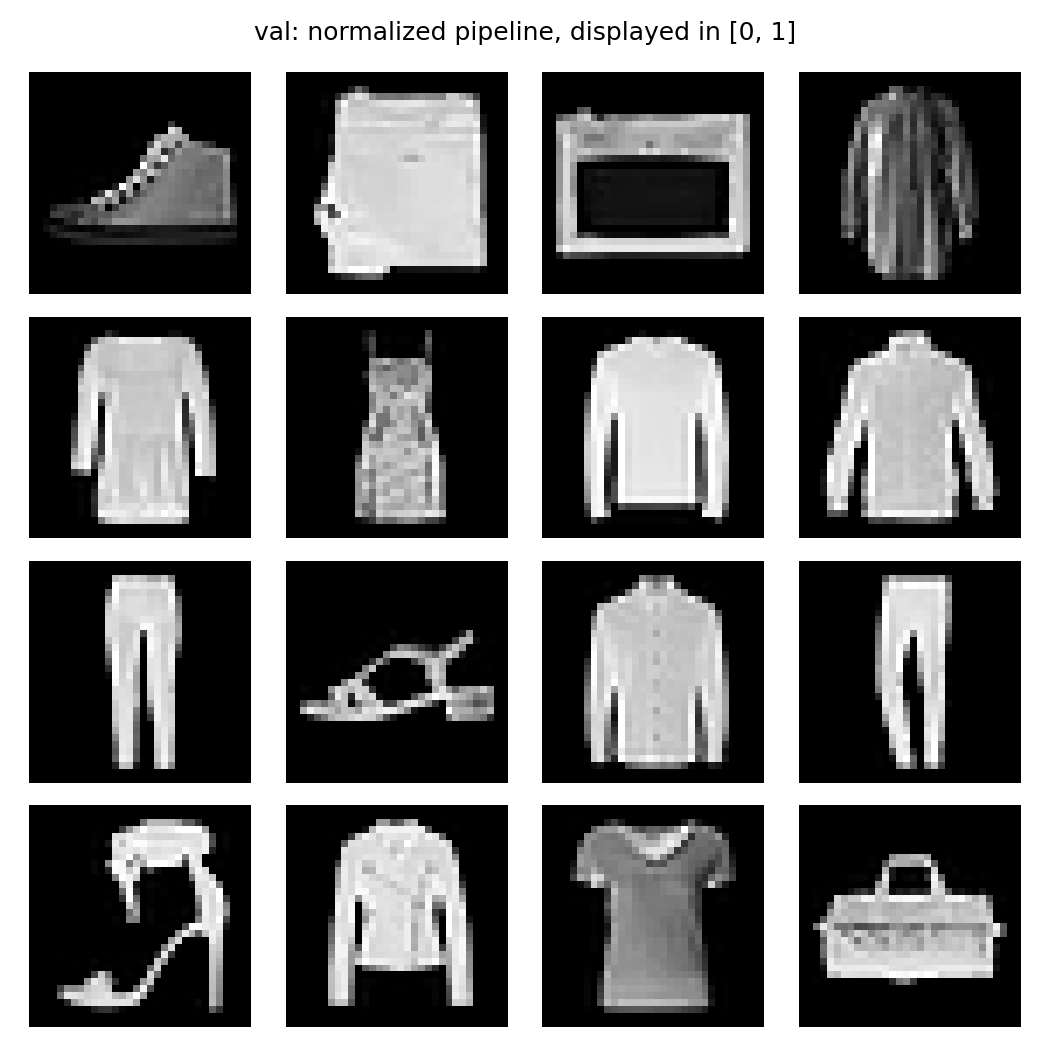

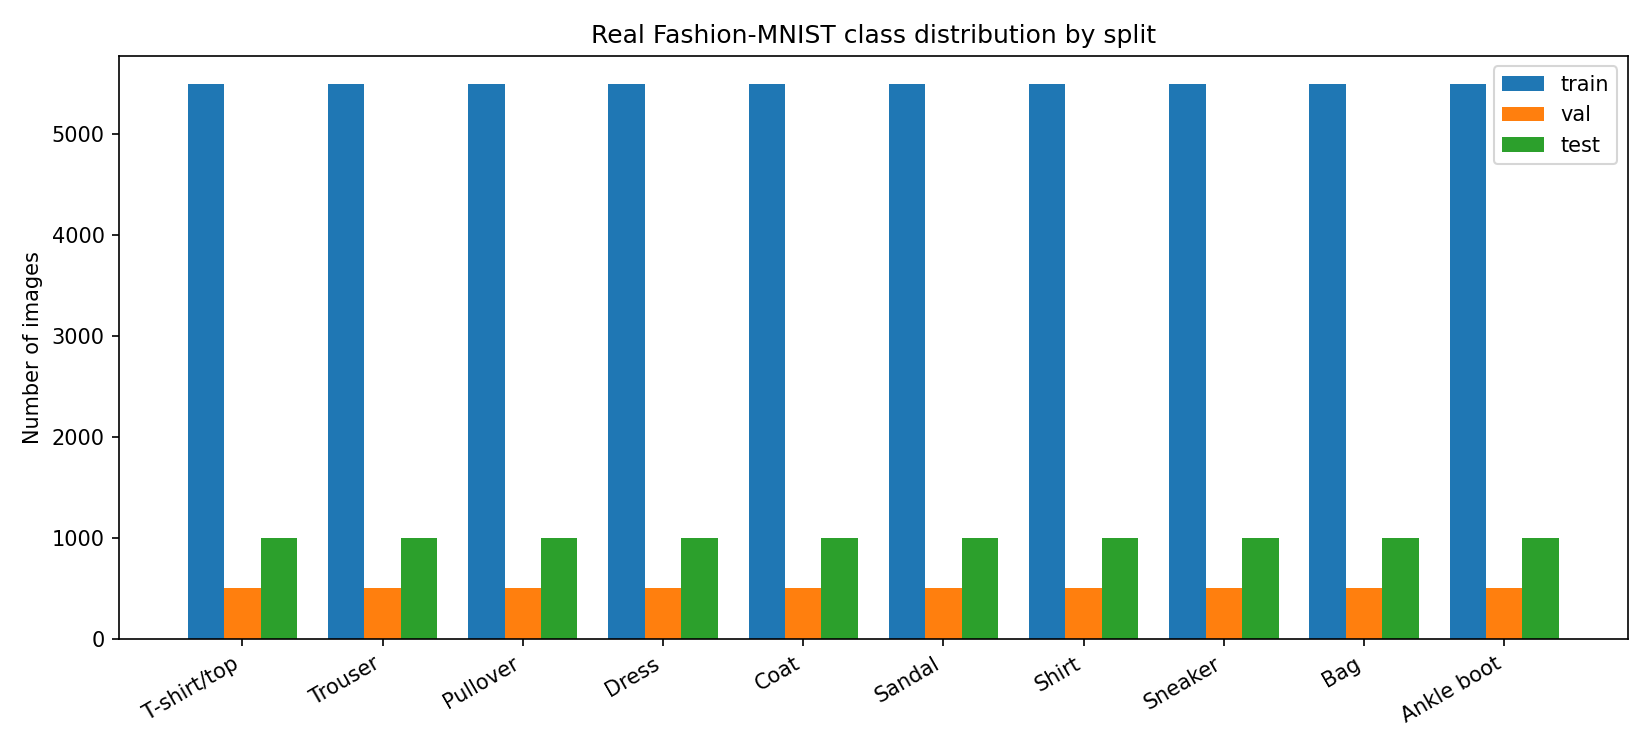

In [6]:
from src.data.inspect import write_report
from IPython.display import Image, display

seed_data(config.seed)
report_loaders = build_dataloaders(config)
summary = write_report(report_loaders, config, Path("reports/data"))
print("Laporan tersimpan: reports/data/summary.json")
print("Indeks split tersimpan: reports/data/split_indices.npz")
display(Image(filename="reports/data/val_preview.png"))
display(Image(filename="reports/data/class_distribution.png"))

## 7. Mengembalikan gambar ke format tampilan

`to_display` melakukan denormalisasi dan crop kembali ke 28×28. Gunakan untuk tampilan/sampling,
bukan sebagai input training yang mengharapkan [-1,1]. Fungsi tidak mengubah tensor asal.

In [7]:
example = loaders.val.dataset[0]
original_copy = example.clone()
displayed = to_display(example)
assert displayed.shape == (1, 28, 28)
assert 0 <= displayed.min() and displayed.max() <= 1
assert torch.equal(example, original_copy)
print("Sebelum tampilan:", tuple(example.shape), "[-1, 1]")
print("Sesudah crop/denormalisasi:", tuple(displayed.shape), "[0, 1]")

Sebelum tampilan: (1, 32, 32) [-1, 1]
Sesudah crop/denormalisasi: (1, 28, 28) [0, 1]


## Serah terima ke anggota training

Gunakan loader baru pada awal run training:

```python
seed_data(config.seed)
loaders = build_dataloaders(config)
for x0 in loaders.train:
    x0 = x0.to(device)
    # loss = diffusion.loss(model, x0)  # Implementasi A1/A3
```

- `x0`: float32 `[B,1,32,32]`, rentang [-1,1]. Batch terakhir boleh lebih kecil.
- Anggota 1: U-Net, timestep embedding dan forward noising.
- Anggota 3: training, validasi diffusion, EMA, checkpoint dan sampling.
- Anggota 4: dokumentasi gabungan dan bukti Git/log.

Tes A2: `python -m pytest -q` dari root repository.
Penjelasan lengkap: `docs/A2_HANDOFF.md`. Log sesi: `logs/llm_interaction/2026-10-26_A2_data_pipeline.md`.
Hasil notebook membuktikan pipeline data; kualitas generasi perlu diuji setelah model dilatih.